In [1]:
# Environment setup & Imports
import os, sys
sys.path.append(os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
from IPython.display import display, HTML

from shared_utils.theme import PALETTE, apply_sleek_theme, create_dashboard_header
from takens_embedding_and_fnn import delay_embed, compute_ami, compute_fnn
from recurrence_quantification import compute_recurrence_matrix, extract_rqa_metrics

apply_sleek_theme()
display(HTML(create_dashboard_header(
    'ACT 07: EMPIRICAL PHASE RECONSTRUCTION & RQA',
    'Interactive GUI Suite: Takens Delay Embedding, AMI, FNN & Recurrence Quantification Analysis'
)))

In [6]:
# Synthetic Signal Generator (Lorenz x-component with controllable Gaussian noise)
def generate_lorenz_signal(n_pts=3000, dt=0.015, noise_lvl=0.02):
    x, y, z = 1.0, 1.0, 1.0
    sig = np.zeros(n_pts)
    for i in range(n_pts):
        dx = 10.0 * (y - x)
        dy = 28.0 * x - y - x * z
        dz = x * y - (8.0 / 3.0) * z
        x += dx * dt
        y += dy * dt
        z += dz * dt
        sig[i] = x
    if noise_lvl > 0:
        sig += np.random.normal(0.0, noise_lvl * np.std(sig), n_pts)
    return sig

raw_signal = generate_lorenz_signal(n_pts=2500, noise_lvl=0.02)
print('[DATA] Generated 2500 sample points of experimental chaotic signal.')

[DATA] Generated 2500 sample points of experimental chaotic signal.


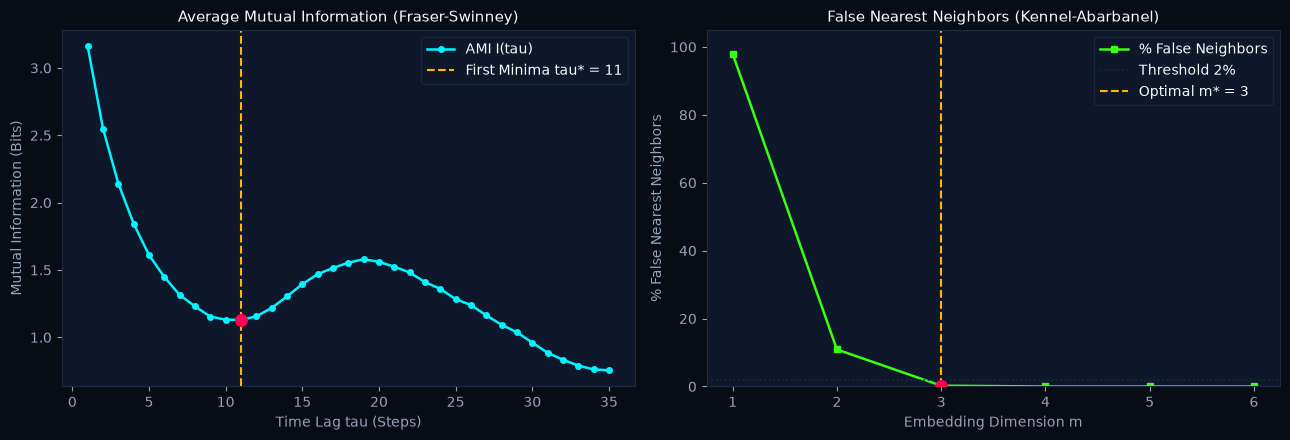

In [3]:
# LAB 7.1: OPTIMAL DELAY (AMI) & EMBEDDING DIMENSION (FNN) EXPLORER
display(HTML(create_dashboard_header(
    'LAB 7.1: TAKENS PARAMETER OPTIMIZATION (AMI & FNN)',
    'Inspect first AMI local minimum for delay tau*, and watch %FNN drop to find embedding dimension m*.'
)))

tau_axis, ami_vals, opt_tau = compute_ami(raw_signal, max_tau=35)
m_axis, fnn_vals, opt_m = compute_fnn(raw_signal, tau=opt_tau, max_m=6)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)

# Panel A: Average Mutual Information
axs[0].plot(tau_axis, ami_vals, 'o-', color=PALETTE['cyan'], lw=1.8, markersize=4, label='AMI I(tau)')
axs[0].axvline(opt_tau, color=PALETTE['amber'], linestyle='--', lw=1.5, label='First Minima tau* = ' + str(opt_tau))
axs[0].scatter([opt_tau], [ami_vals[opt_tau - 1]], color=PALETTE['crimson'], s=70, zorder=6)
axs[0].set_title('Average Mutual Information (Fraser-Swinney)', fontsize=11)
axs[0].set_xlabel('Time Lag tau (Steps)', fontsize=10)
axs[0].set_ylabel('Mutual Information (Bits)', fontsize=10)
axs[0].legend(loc='upper right')

# Panel B: False Nearest Neighbors
axs[1].plot(m_axis, fnn_vals, 's-', color=PALETTE['emerald'], lw=1.8, markersize=5, label='% False Neighbors')
axs[1].axhline(2.0, color=PALETTE['border'], linestyle=':', lw=1.2, label='Threshold 2%')
axs[1].axvline(opt_m, color=PALETTE['amber'], linestyle='--', lw=1.5, label='Optimal m* = ' + str(opt_m))
axs[1].scatter([opt_m], [fnn_vals[opt_m - 1]], color=PALETTE['crimson'], s=70, zorder=6)
axs[1].set_title('False Nearest Neighbors (Kennel-Abarbanel)', fontsize=11)
axs[1].set_xlabel('Embedding Dimension m', fontsize=10)
axs[1].set_ylabel('% False Nearest Neighbors', fontsize=10)
axs[1].set_ylim(0, 105)
axs[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

In [4]:
# LAB 7.2: 3D RECONSTRUCTED PHASE SPACE VIEWER
display(HTML(create_dashboard_header(
    'LAB 7.2: 3D RECONSTRUCTED PHASE SPACE TOPOGRAPHY',
    'Scrub delay tau: Watch trajectory collapse onto diagonal if tau is too small, or unfold into strange attractor.'
)))

def render_reconstruction(tau_slider, elev, azim):
    emb = delay_embed(raw_signal, tau=tau_slider, m=3)
    
    fig = plt.figure(figsize=(10, 6), dpi=100)
    ax = fig.add_subplot(1, 1, 1, projection='3d')
    ax.set_facecolor(PALETTE['surface'])
    ax.plot(emb[:, 0], emb[:, 1], emb[:, 2], color=PALETTE['cyan'], lw=0.7, alpha=0.85)
    
    ax.view_init(elev=elev, azim=azim)
    state_text = 'Collapsed Redundancy' if tau_slider < 4 else ('Unfolded Strange Attractor' if tau_slider < 25 else 'De-correlated Spread')
    ax.set_title('Reconstructed 3D Space [s(t), s(t+tau), s(t+2tau)] | ' + state_text, fontsize=11)
    ax.set_xlabel('s(t)', fontsize=9)
    ax.set_ylabel('s(t+tau)', fontsize=9)
    ax.set_zlabel('s(t+2tau)', fontsize=9)
    plt.tight_layout()
    plt.show()

s_tau = widgets.IntSlider(value=opt_tau, min=1, max=30, step=1, description='Delay tau:', layout=widgets.Layout(width='380px'))
s_el = widgets.IntSlider(value=25, min=0, max=90, step=5, description='Elevation:', layout=widgets.Layout(width='260px'))
s_az = widgets.IntSlider(value=45, min=-180, max=180, step=5, description='Azimuth:', layout=widgets.Layout(width='260px'))

ui_rec = widgets.HBox([s_tau, s_el, s_az], layout=widgets.Layout(padding='10px', background_color=PALETTE['surface'], border='1px solid ' + PALETTE['border'], border_radius='8px'))
out_rec = widgets.interactive_output(render_reconstruction, {'tau_slider': s_tau, 'elev': s_el, 'azim': s_az})
display(ui_rec, out_rec)

Output()

In [5]:
# LAB 7.3: RECURRENCE PLOT & LIVE RQA METRICS ENGINE
display(HTML(create_dashboard_header(
    'LAB 7.3: RECURRENCE PLOT & RECURRENCE QUANTIFICATION (RQA)',
    'Adjust threshold epsilon percentile: Observe diagonal patterns of determinism and live RQA metric gauges.'
)))

pts_subset = delay_embed(raw_signal[:600], tau=opt_tau, m=3)

def render_rqa_dashboard(rr_percentile):
    dist_m, rec_m, eps_val = compute_recurrence_matrix(pts_subset, fixed_rr=rr_percentile / 100.0)
    metrics = extract_rqa_metrics(rec_m, l_min=2, v_min=2)
    
    fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), dpi=100)
    
    # Panel A: Binary Recurrence Plot
    axs[0].imshow(rec_m, cmap='binary', origin='lower', interpolation='none')
    axs[0].set_title('Recurrence Plot (N = 600) | eps = ' + str(round(eps_val, 3)), fontsize=11)
    axs[0].set_xlabel('State Vector Index i', fontsize=10)
    axs[0].set_ylabel('State Vector Index j', fontsize=10)
    
    # Panel B: Quantitative RQA Bar Gauges
    keys = ['RR', 'DET', 'LAM']
    vals = [metrics['RR'] * 100, metrics['DET'] * 100, metrics['LAM'] * 100]
    colors = [PALETTE['cyan'], PALETTE['emerald'], PALETTE['amber']]
    
    bars = axs[1].bar(keys, vals, color=colors, width=0.5)
    axs[1].set_ylim(0, 105)
    axs[1].set_ylabel('Percentage (%)', fontsize=10)
    axs[1].set_title('RQA Structural Indicators | L_max = ' + str(metrics['L_max']) + ' | ENTR = ' + str(round(metrics['ENTR'], 2)), fontsize=11)
    for bar in bars:
        yval = bar.get_height()
        axs[1].text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, str(round(yval, 1)) + '%', ha='center', va='bottom', color=PALETTE['text_main'], fontsize=10, weight='bold')
    
    plt.tight_layout()
    plt.show()

s_rr = widgets.FloatSlider(value=8.0, min=2.0, max=25.0, step=1.0, description='RR Threshold %:', layout=widgets.Layout(width='450px'))
ui_rqa = widgets.HBox([s_rr], layout=widgets.Layout(padding='10px', background_color=PALETTE['surface'], border='1px solid ' + PALETTE['border'], border_radius='8px'))
out_rqa = widgets.interactive_output(render_rqa_dashboard, {'rr_percentile': s_rr})
display(ui_rqa, out_rqa)

Output()